# Subscription Retention & LTV: who to offer what, and what it is worth
**Business question:** which subscribers should receive which retention offer, and how much is it worth?
**Data:** IBM Telco Customer Churn (Kaggle): 7,043 customers, one snapshot in time.

**TL;DR**
- 2 of 6 segments (29% of customers) explain **68% of lost monthly revenue**.
- A blanket 15% discount would **destroy about USD 239k** of lifetime value: most recipients would have stayed anyway.
- Recommended: **annual contract + 1 free month** for month-to-month customers (**+USD 48k** lifetime EV) and **no offer** for contract customers.
- It pays off only if churn falls by **about 23% among customers who accept** (22-29% by segment), so it should start as a **12-month pilot with a randomized control group**. With 25% take-up, the current base can confirm the assumed effect but not the break-even.

**Method:** cleaning, exploration (pandas + SQL with DuckDB), segmentation, logistic regression, discounted LTV, expected-value decision model, sensitivity and break-even, pilot sample size (power analysis), KPI scorecard and forecast. Assumptions and limitations are stated where they are used and at the end.

In [166]:
import pandas as pd
import numpy as np

# Data source: the raw CSV stored in the project's GitHub repo, so "Run all" works with no manual upload.
# Fallback: a local copy (e.g. uploaded to Colab's Files panel) while the repo is not public yet.
DATA_URL = "https://raw.githubusercontent.com/belen-shell-merier/subscription-retention-ltv/main/data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
LOCAL_FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

try:
    df = pd.read_csv(DATA_URL)
    print("Data loaded from GitHub")
except Exception:
    df = pd.read_csv(LOCAL_FILE)
    print("GitHub copy not available yet: data loaded from the local file")

print(df.shape)
df.info()

GitHub copy not available yet: data loaded from the local file
(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract       

In [167]:
# Step 1: data cleaning
# 1) TotalCharges: find the blank values and check which customers they belong to
blancos = df["TotalCharges"].str.strip() == ""
print("Customers with blank TotalCharges:", blancos.sum())
print("Tenure of those customers:", df.loc[blancos, "tenure"].unique())

# Decision: they are new sign-ups not billed yet -> TotalCharges = 0
df.loc[blancos, "TotalCharges"] = "0"
df["TotalCharges"] = df["TotalCharges"].astype(float)

# 2) Churn: from Yes/No to 1/0
df["Churn"] = (df["Churn"] == "Yes").astype(int)

# 3) Checks
print("Duplicated customers:", df["customerID"].duplicated().sum())
print(df[["TotalCharges", "Churn"]].dtypes)
print("Overall churn:", round(df["Churn"].mean() * 100, 1), "%")

Customers with blank TotalCharges: 11
Tenure of those customers: [0]
Duplicated customers: 0
TotalCharges    float64
Churn             int64
dtype: object
Overall churn: 26.5 %


### Data cleaning rules
- **TotalCharges:** loaded as text. 11 customers had a blank value, all with `tenure = 0` (signed up this month, not billed yet). Set to **0**, not dropped and not imputed: they are real new customers, not errors.
- **Churn:** converted from Yes/No to **1/0**, so its mean is the churn rate.
- **Checks:** 7,043 customers, no duplicated `customerID`. Overall churn: **26.5%**.

In [168]:
# Step 2: exploration - churn by variable
# Tenure groups (months) and monthly charge groups (quartiles)
df["tenure_grupo"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12 m", "13-24 m", "25-48 m", "49-72 m"])
df["cargo_grupo"] = pd.qcut(df["MonthlyCharges"], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])

# count = customers in the group, mean = churn rate of the group
print(df.groupby("Contract")["Churn"].agg(["count", "mean"]).round(3), "\n")
print(df.groupby("tenure_grupo", observed=True)["Churn"].agg(["count", "mean"]).round(3), "\n")
print(df.groupby("PaymentMethod")["Churn"].agg(["count", "mean"]).round(3), "\n")
print(df.groupby("cargo_grupo", observed=True)["Churn"].agg(["count", "mean"]).round(3), "\n")
print(df.groupby("InternetService")["Churn"].agg(["count", "mean"]).round(3))

                count   mean
Contract                    
Month-to-month   3875  0.427
One year         1473  0.113
Two year         1695  0.028 

              count   mean
tenure_grupo              
0-12 m         2186  0.474
13-24 m        1024  0.287
25-48 m        1594  0.204
49-72 m        2239  0.095 

                           count   mean
PaymentMethod                          
Bank transfer (automatic)   1544  0.167
Credit card (automatic)     1522  0.152
Electronic check            2365  0.453
Mailed check                1612  0.191 

             count   mean
cargo_grupo              
Q1 low        1762  0.112
Q2            1766  0.246
Q3            1757  0.375
Q4 high       1758  0.329 

                 count   mean
InternetService              
DSL               2421  0.190
Fiber optic       3096  0.419
No                1526  0.074


In [169]:
# Step 2b: the same question in SQL (DuckDB queries the pandas DataFrame df directly)
import duckdb

consulta = "SELECT Contract, PaymentMethod, COUNT(*) AS customers, ROUND(AVG(Churn) * 100, 1) AS churn_pct, ROUND(SUM(MonthlyCharges)) AS monthly_revenue, ROUND(100 * SUM(MonthlyCharges) / SUM(SUM(MonthlyCharges)) OVER (), 1) AS revenue_pct FROM df GROUP BY Contract, PaymentMethod ORDER BY churn_pct DESC"

duckdb.sql(consulta).df()

,Contract,PaymentMethod,customers,churn_pct,monthly_revenue,revenue_pct
0,Month-to-month,Electronic check,1850,53.7,138731.0,30.4
1,Month-to-month,Bank transfer (automatic),589,34.1,40691.0,8.9
2,Month-to-month,Credit card (automatic),543,32.8,36750.0,8.1
3,Month-to-month,Mailed check,893,31.6,41123.0,9.0
4,One year,Electronic check,347,18.4,27446.0,6.0
5,One year,Credit card (automatic),398,10.3,27053.0,5.9
6,One year,Bank transfer (automatic),391,9.7,26386.0,5.8
7,Two year,Electronic check,168,7.7,14168.0,3.1
8,One year,Mailed check,337,6.8,14931.0,3.3
9,Two year,Bank transfer (automatic),564,3.4,36668.0,8.0


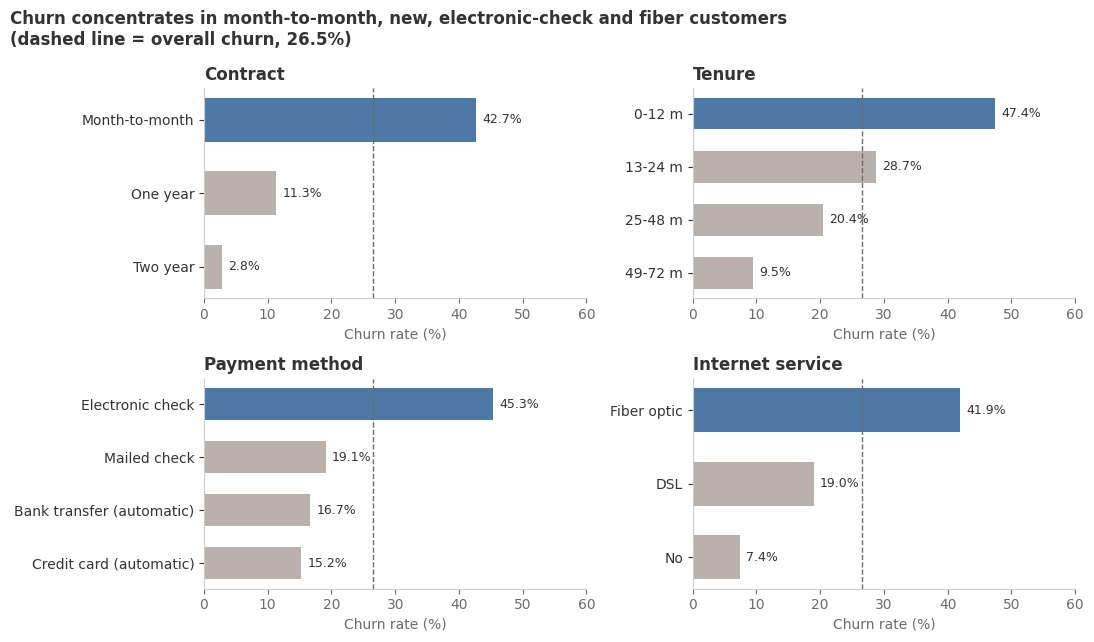

In [170]:
# Step 2c: chart - churn rate by variable (blue = highest-risk group in each panel)
import os
import matplotlib.pyplot as plt
os.makedirs("charts", exist_ok=True)   # PNG copies of the charts for the README

# Same palette as the Tableau dashboard: one accent color for what matters, gray for the rest
BLUE, GRAY, INK, MUTED = "#4E79A7", "#BAB0AC", "#333333", "#6B6B6B"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#CCCCCC",
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": INK})

variables = {"Contract": "Contract", "tenure_grupo": "Tenure", "PaymentMethod": "Payment method", "InternetService": "Internet service"}
churn_total = df["Churn"].mean() * 100

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, (col, titulo) in zip(axes.flat, variables.items()):
    tasa = df.groupby(col, observed=True)["Churn"].mean().mul(100)
    tasa = tasa[::-1] if col == "tenure_grupo" else tasa.sort_values()   # tenure keeps its natural order (0-12 m on top)
    colores = [BLUE if v == tasa.max() else GRAY for v in tasa]
    ax.barh(tasa.index.astype(str), tasa.values, color=colores, height=0.6)
    for y, v in enumerate(tasa.values):
        ax.text(v + 1, y, f"{v:.1f}%", va="center", color=INK, fontsize=9)
    ax.axvline(churn_total, color=MUTED, linestyle="--", linewidth=1)
    ax.set_title(titulo, loc="left", color=INK, fontweight="bold")
    ax.set_xlim(0, 60)
    ax.set_xlabel("Churn rate (%)")

fig.suptitle(f"Churn concentrates in month-to-month, new, electronic-check and fiber customers\n(dashed line = overall churn, {churn_total:.1f}%)",
             x=0.01, ha="left", color=INK, fontweight="bold")
fig.tight_layout()
fig.savefig("charts/churn_by_variable.png", dpi=150, bbox_inches="tight")
plt.show()

In [171]:
# Step 3: segments (option C: contract x tenure x value)
corte_valor = df["MonthlyCharges"].median()
print("Value cut (median monthly charge):", corte_valor)

mes_a_mes = df["Contract"] == "Month-to-month"
nuevo = df["tenure"] <= 12
alto = df["MonthlyCharges"] > corte_valor

condiciones = [mes_a_mes & nuevo & alto, mes_a_mes & nuevo & ~alto, mes_a_mes & ~nuevo & alto, mes_a_mes & ~nuevo & ~alto, ~mes_a_mes & alto, ~mes_a_mes & ~alto]
nombres = ["1 No contract, new, high bill", "2 No contract, new, low bill", "3 No contract, tenured, high bill", "4 No contract, tenured, low bill", "5 Contract, high bill", "6 Contract, low bill"]
df["segmento"] = np.select(condiciones, nombres, default="unassigned")
df["mes_a_mes"] = mes_a_mes
assert (df["segmento"] != "unassigned").all()

# Monthly revenue of customers who left
df["ingreso_perdido"] = df["MonthlyCharges"] * df["Churn"]

# Full precision for every calculation; rounding only when displaying
resumen = df.groupby("segmento").agg(clientes=("Churn", "size"), mes_a_mes=("mes_a_mes", "first"), churn=("Churn", "mean"), arpu=("MonthlyCharges", "mean"), ingreso_mensual=("MonthlyCharges", "sum"), ingreso_perdido=("ingreso_perdido", "sum"))
resumen["pct_clientes"] = 100 * resumen["clientes"] / resumen["clientes"].sum()
resumen["pct_ingresos"] = 100 * resumen["ingreso_mensual"] / resumen["ingreso_mensual"].sum()
resumen["pct_ingreso_perdido"] = 100 * resumen["ingreso_perdido"] / resumen["ingreso_perdido"].sum()
resumen.assign(churn_pct=100 * resumen["churn"]).drop(columns="churn").round(1)

Value cut (median monthly charge): 70.35


,clientes,mes_a_mes,arpu,ingreso_mensual,ingreso_perdido,pct_clientes,pct_ingresos,pct_ingreso_perdido,churn_pct
segmento,,,,,,,,,
"1 No contract, new, high bill",812,True,83.8,68032.2,47981.8,11.5,14.9,34.5,70.0
"2 No contract, new, low bill",1182,True,40.7,48054.2,20319.6,16.8,10.5,14.6,38.6
"3 No contract, tenured, high bill",1231,True,90.7,111701.9,46770.0,17.5,24.5,33.6,41.5
"4 No contract, tenured, low bill",650,True,45.4,29505.8,5775.6,9.2,6.5,4.2,18.5
"5 Contract, high bill",1472,False,94.3,138794.6,15633.6,20.9,30.4,11.2,10.7
"6 Contract, low bill",1696,False,35.4,60027.8,2650.2,24.1,13.2,1.9,3.3


### Segmentation rule
Six segments built on the two strongest churn drivers from the exploration (contract and tenure) plus customer value:
- **Month-to-month** customers split by **tenure** (new = 12 months or less) and **value** (monthly charge above/below the median, $70.35): segments 1-4.
- **Contract** customers (one or two years) split only by value: segments 5-6. Their churn is low and similar, so splitting further would not change the decision.

Key finding: segments 1 and 3 are **29% of customers but 68% of lost monthly revenue**. Segment 6 is 24% of customers and only 1.9% of lost revenue.

In [172]:
# Step 4: logistic regression - what explains churn
import statsmodels.formula.api as smf

# Variables in units that are easy to interpret
df["tenure_anios"] = df["tenure"] / 12          # +1 year of tenure
df["cargo_10"] = df["MonthlyCharges"] / 10      # +10 USD of monthly charge
df["TechSupport_si"] = (df["TechSupport"] == "Yes").astype(int)
df["OnlineSecurity_si"] = (df["OnlineSecurity"] == "Yes").astype(int)
df["PaperlessBilling_si"] = (df["PaperlessBilling"] == "Yes").astype(int)

# Reference categories: the highest-risk ones (month-to-month, electronic check, fiber optic)
# TotalCharges is left out: it is roughly tenure x monthly charge (multicollinearity)
formula = "Churn ~ tenure_anios + cargo_10 + C(Contract, Treatment('Month-to-month')) + C(PaymentMethod, Treatment('Electronic check')) + C(InternetService, Treatment('Fiber optic')) + TechSupport_si + OnlineSecurity_si + PaperlessBilling_si + SeniorCitizen"

modelo = smf.logit(formula, data=df).fit()
print(modelo.summary())

Optimization terminated successfully.
         Current function value: 0.419793
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 7043
Model:                          Logit   Df Residuals:                     7029
Method:                           MLE   Df Model:                           13
Date:                Wed, 18 Nov 2026   Pseudo R-squ.:                  0.2745
Time:                        21:02:02   Log-Likelihood:                -2956.6
converged:                       True   LL-Null:                       -4075.1
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                                                   coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------

In [173]:
# Step 4b: odds ratios = exp(coefficient), with 95% confidence interval
ic = np.exp(modelo.conf_int())
or_tabla = pd.DataFrame({"odds_ratio": np.exp(modelo.params), "ci_low": ic[0], "ci_high": ic[1], "p_value": modelo.pvalues})
or_tabla["odds_change_pct"] = (or_tabla["odds_ratio"] - 1) * 100

# Readable labels mapped by parameter name, not by position: if the model changes, labels cannot get misaligned
etiquetas = {"Intercept": "Intercept", "C(Contract, Treatment('Month-to-month'))[T.One year]": "One-year contract (vs month-to-month)", "C(Contract, Treatment('Month-to-month'))[T.Two year]": "Two-year contract (vs month-to-month)", "C(PaymentMethod, Treatment('Electronic check'))[T.Bank transfer (automatic)]": "Bank transfer (vs electronic check)", "C(PaymentMethod, Treatment('Electronic check'))[T.Credit card (automatic)]": "Credit card (vs electronic check)", "C(PaymentMethod, Treatment('Electronic check'))[T.Mailed check]": "Mailed check (vs electronic check)", "C(InternetService, Treatment('Fiber optic'))[T.DSL]": "DSL (vs fiber)", "C(InternetService, Treatment('Fiber optic'))[T.No]": "No internet (vs fiber)", "tenure_anios": "+1 year of tenure", "cargo_10": "+USD 10 monthly charge", "TechSupport_si": "Has tech support", "OnlineSecurity_si": "Has online security", "PaperlessBilling_si": "Paperless billing", "SeniorCitizen": "Senior citizen"}
or_tabla = or_tabla.rename(index=etiquetas)

print("Pseudo R2:", round(modelo.prsquared, 3), "| Customers:", int(modelo.nobs))
or_tabla.round(3)

Pseudo R2: 0.274 | Customers: 7043


,odds_ratio,ci_low,ci_high,p_value,odds_change_pct
Intercept,0.877,0.509,1.512,0.637,-12.262
One-year contract (vs month-to-month),0.509,0.414,0.626,0.000,-49.080
Two-year contract (vs month-to-month),0.257,0.183,0.361,0.000,-74.317
Bank transfer (vs electronic check),0.696,0.579,0.836,0.000,-30.412
Credit card (vs electronic check),0.642,0.531,0.776,0.000,-35.789
Mailed check (vs electronic check),0.678,0.564,0.816,0.000,-32.153
DSL (vs fiber),0.596,0.453,0.785,0.000,-40.405
No internet (vs fiber),0.274,0.171,0.439,0.000,-72.621
+1 year of tenure,0.684,0.650,0.719,0.000,-31.610
+USD 10 monthly charge,1.115,1.045,1.189,0.001,11.484


In [174]:
# Step 4c: multicollinearity check - variance inflation factor (VIF) of each predictor
# VIF = 1 / (1 - R^2 of that predictor regressed on all the others). Rule of thumb: < 5 fine, 5-10 watch, > 10 problem
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = pd.DataFrame(modelo.model.exog, columns=modelo.model.exog_names)   # the same design matrix the model used
vif = pd.DataFrame({"predictor": X.columns, "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
vif = vif[vif["predictor"] != "Intercept"].sort_values("VIF", ascending=False)   # the intercept's VIF is not interpreted
print(vif.round(2).to_string(index=False))

# Why TotalCharges was left out: its VIF if it were added to the same predictors
X_tc = X.assign(TotalCharges=df["TotalCharges"].values)
print("\nVIF of TotalCharges if added:", round(variance_inflation_factor(X_tc.values, X_tc.shape[1] - 1), 1))

                                                                   predictor  VIF
                          C(InternetService, Treatment('Fiber optic'))[T.No] 9.60
                                                                    cargo_10 9.19
                         C(InternetService, Treatment('Fiber optic'))[T.DSL] 4.44
                        C(Contract, Treatment('Month-to-month'))[T.Two year] 2.57
                                                                tenure_anios 2.44
             C(PaymentMethod, Treatment('Electronic check'))[T.Mailed check] 1.68
                                                              TechSupport_si 1.60
                        C(Contract, Treatment('Month-to-month'))[T.One year] 1.60
  C(PaymentMethod, Treatment('Electronic check'))[T.Credit card (automatic)] 1.52
C(PaymentMethod, Treatment('Electronic check'))[T.Bank transfer (automatic)] 1.51
                                                           OnlineSecurity_si 1.47
                

### Multicollinearity check (VIF)
- **Contract type and tenure**, the drivers behind the recommendation, have VIF below 3: their odds ratios are reliable.
- **Monthly charge (9.2) and "no internet service" (9.6)** are close to 10. That is expected: the bill depends largely on the internet type. Both stay in the model, but their odds ratios are read "for the same internet type" and are less precise. The decision does not depend on them.
- **TotalCharges** would have a VIF of 10.4 (it is roughly tenure x monthly charge), which confirms that leaving it out was the right call.

In [175]:
# Step 5: discounted LTV by segment, CAC and payback
# Assumptions (documented in the text cell below)
MARGEN = 0.60
TASA_ANUAL = 0.10
CAC = 300
HORIZONTE = 60

# Churn period: the data dictionary defines Churn as customers who left "within the last month".
# Taken literally, a 26.5% monthly churn implies an average customer life of about 4 months,
# which is inconsistent with the average tenure of the current base. So the flag is treated as an annual rate.
print("Average tenure of the base (months):", round(df["tenure"].mean(), 1))
print("Average life implied if churn were monthly (months):", round(1 / df["Churn"].mean(), 1))

d = (1 + TASA_ANUAL) ** (1 / 12) - 1
print("Monthly discount rate:", round(d, 4))

ltv = resumen[["clientes", "mes_a_mes", "churn", "arpu"]].rename(columns={"churn": "churn_anual"})
ltv["churn_mensual"] = 1 - (1 - ltv["churn_anual"]) ** (1 / 12)
ltv["margen_mensual"] = MARGEN * ltv["arpu"]

# Present value of 60 months of margin: each month a share c of customers leaves (1-c) and cash flows are discounted (1+d)
q = (1 - ltv["churn_mensual"]) / (1 + d)
ltv["ltv"] = ltv["margen_mensual"] * (1 - q ** HORIZONTE) / (1 - q)

ltv["vida_media_meses"] = 1 / ltv["churn_mensual"]
ltv["payback_meses"] = CAC / ltv["margen_mensual"]
ltv["ltv_cac"] = ltv["ltv"] / CAC
ltv.round(3)

Average tenure of the base (months): 32.4
Average life implied if churn were monthly (months): 3.8
Monthly discount rate: 0.008


,clientes,mes_a_mes,churn_anual,arpu,churn_mensual,margen_mensual,ltv,vida_media_meses,payback_meses,ltv_cac
segmento,,,,,,,,,,
"1 No contract, new, high bill",812,True,0.700,83.784,0.095,50.270,489.717,10.489,5.968,1.632
"2 No contract, new, low bill",1182,True,0.386,40.655,0.040,24.393,486.687,25.123,12.299,1.622
"3 No contract, tenured, high bill",1231,True,0.415,90.741,0.044,54.444,1016.675,22.878,5.510,3.389
"4 No contract, tenured, low bill",650,True,0.185,45.393,0.017,27.236,857.925,59.297,11.015,2.860
"5 Contract, high bill",1472,False,0.107,94.290,0.009,56.574,2124.886,106.185,5.303,7.083
"6 Contract, low bill",1696,False,0.033,35.394,0.003,21.236,944.305,357.895,14.127,3.148


### LTV assumptions (not in the data, stated explicitly)
| Assumption | Value | Why |
|---|---|---|
| Churn period | Churn flag treated as **annual**, converted to monthly: 1-(1-p)^(1/12) | The data dictionary defines Churn as customers who left "within the last month". Taken literally, 26.5% monthly churn implies a ~4-month average life, inconsistent with the 32-month average tenure computed above. This is the main modeling assumption |
| Contribution margin | **60%** of monthly charge | Typical for telecom services |
| Discount rate | **10% annual** (0.8% monthly) | Cost of capital of an established company |
| Horizon | **60 months** | Avoids unrealistic 20+ year lives in low-churn segments |
| CAC | **USD 300** (hypothetical) | Not in the data; used only to compare retention vs. acquisition |

LTV = present value of 60 months of margin, where each month a share *c* of customers leaves and cash flows are discounted at *d*.

In [176]:
# Step 6: decision model - expected value (EV) of each offer in each segment
# Offer assumptions (documented in the text cell below). Each offer has an id and an eligibility rule
ofertas = pd.DataFrame({"id": ["A", "B", "C"], "oferta": ["A 15% discount x 12 months", "B Annual contract + 1 free month", "C Free support & security x 12 months"], "aceptacion": [1.00, 0.25, 0.60], "reduccion_churn": [0.20, 0.40, 0.15], "solo_mes_a_mes": [False, True, False]})

# Cross every segment with every offer, then drop combinations that make no business sense:
# offer B (move to an annual contract) only applies to month-to-month customers
tabla = ltv.reset_index()[["segmento", "clientes", "mes_a_mes", "arpu", "churn_anual", "ltv"]].merge(ofertas, how="cross")
tabla = tabla[tabla["mes_a_mes"] | ~tabla["solo_mes_a_mes"]].reset_index(drop=True)

# Cost per accepting customer: A = 15% of the bill for 12 months, B = one free month, C = USD 3/month x 12
tabla["costo"] = np.select([tabla["id"] == "A", tabla["id"] == "B"], [0.15 * tabla["arpu"] * 12, tabla["arpu"]], default=36)

# Customers saved per accepting customer = annual churn x churn reduction
tabla["salvados"] = tabla["churn_anual"] * tabla["reduccion_churn"]

# EV per targeted customer = take-up x (saved x LTV - cost). The cost is also paid for customers who would have stayed
tabla["ve_por_cliente"] = tabla["aceptacion"] * (tabla["salvados"] * tabla["ltv"] - tabla["costo"])
tabla["ve_segmento"] = tabla["ve_por_cliente"] * tabla["clientes"]

tabla.pivot(index="segmento", columns="oferta", values="ve_por_cliente").round(1)

oferta,A 15% discount x 12 months,B Annual contract + 1 free month,C Free support & security x 12 months
segmento,,,
"1 No contract, new, high bill",-82.3,13.3,9.2
"2 No contract, new, low bill",-35.6,8.6,-4.7
"3 No contract, tenured, high bill",-78.9,19.5,16.4
"4 No contract, tenured, low bill",-50.0,4.5,-7.3
"5 Contract, high bill",-124.1,NaN,-1.1
"6 Contract, low bill",-57.5,NaN,-18.8


In [177]:
# Step 6b: best offer per segment (only if its EV is positive; otherwise, no offer)
mejor = tabla.loc[tabla.groupby("segmento")["ve_segmento"].idxmax(), ["segmento", "id", "oferta", "clientes", "ve_por_cliente", "ve_segmento"]]
mejor["decision"] = np.where(mejor["ve_segmento"] > 0, mejor["oferta"], "No offer")
mejor.loc[mejor["ve_segmento"] <= 0, ["ve_por_cliente", "ve_segmento"]] = 0

# Benchmark: the classic mistake of giving discount A to every month-to-month customer
descuento_a_todos = tabla.loc[(tabla["id"] == "A") & tabla["mes_a_mes"], "ve_segmento"].sum()

# EV is measured over the customer lifetime (60 months, discounted), not per year
print("EV of the targeted plan (USD, lifetime):", round(mejor["ve_segmento"].sum()))
print("EV of discount A to every month-to-month customer (USD, lifetime):", round(descuento_a_todos))
mejor[["segmento", "decision", "clientes", "ve_por_cliente", "ve_segmento"]].round(1)

EV of the targeted plan (USD, lifetime): 47933
EV of discount A to every month-to-month customer (USD, lifetime): -238617


,segmento,decision,clientes,ve_por_cliente,ve_segmento
1,"1 No contract, new, high bill",B Annual contract + 1 free month,812,13.3,10807.9
4,"2 No contract, new, low bill",B Annual contract + 1 free month,1182,8.6,10179.4
7,"3 No contract, tenured, high bill",B Annual contract + 1 free month,1231,19.5,24026.6
10,"4 No contract, tenured, low bill",B Annual contract + 1 free month,650,4.5,2918.7
13,"5 Contract, high bill",No offer,1472,0.0,0.0
15,"6 Contract, low bill",No offer,1696,0.0,0.0


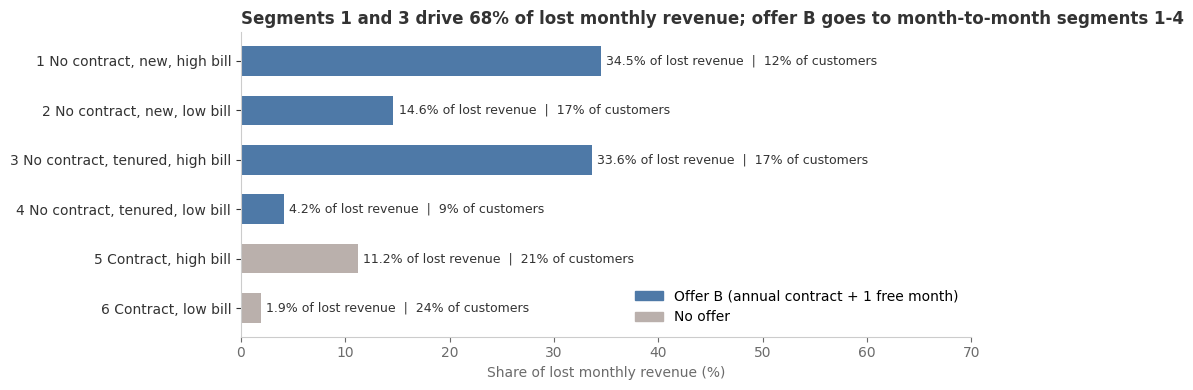

In [178]:
# Step 6c: chart - where revenue is lost, and which segments get offer B
graf = resumen.reset_index()[["segmento", "pct_ingreso_perdido", "pct_clientes"]].merge(mejor[["segmento", "decision"]], on="segmento")
graf = graf.sort_values("segmento", ascending=False)   # segment 1 on top
colores = [BLUE if d.startswith("B") else GRAY for d in graf["decision"]]

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(graf["segmento"], graf["pct_ingreso_perdido"], color=colores, height=0.6)
for y, (p, c) in enumerate(zip(graf["pct_ingreso_perdido"], graf["pct_clientes"])):
    ax.text(p + 0.5, y, f"{p:.1f}% of lost revenue  |  {c:.0f}% of customers", va="center", color=INK, fontsize=9)

ax.set_xlim(0, 70)
ax.set_xlabel("Share of lost monthly revenue (%)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=GRAY)],
          labels=["Offer B (annual contract + 1 free month)", "No offer"], loc="lower right", frameon=False)
top2 = graf.nlargest(2, "pct_ingreso_perdido")["pct_ingreso_perdido"].sum()   # computed, not typed
ax.set_title(f"Segments 1 and 3 drive {top2:.0f}% of lost monthly revenue; offer B goes to month-to-month segments 1-4", loc="left", color=INK, fontweight="bold")
fig.tight_layout()
fig.savefig("charts/lost_revenue_by_segment.png", dpi=150, bbox_inches="tight")
plt.show()

### Retention offers: assumptions and decision rule
| Offer | Eligible segments | Cost per accepting customer | Take-up | Churn reduction | Basis |
|---|---|---|---|---|---|
| A. 15% discount for 12 months | All | 15% x monthly charge x 12 | 100% | -20% | Moderate effect for a standard discount |
| B. Annual contract + 1 free month | Month-to-month only (1-4) | 1 x monthly charge | 25% | -40% | Logit: one-year contract odds -49%; reduced for self-selection |
| C. Free tech support + online security, 12 months | All | USD 3/month x 12 = USD 36 | 60% | -15% | Logit: -32% / -37% odds; less than half taken |

**Expected value per targeted customer** = take-up x (annual churn x churn reduction x LTV - offer cost), measured over the customer lifetime (60 months, discounted). The cost is paid for every customer who accepts, including those who would have stayed anyway.

**Decision rule:** each segment gets only the eligible offer with the highest positive EV (one offer per segment avoids double-counting saved customers); if no offer has positive EV, offer nothing.

**Result:** offer B in segments 1-4, nothing in segments 5-6. Lifetime expected value **+USD 47.9k**, vs. **-USD 238.6k** for giving the 15% discount to every month-to-month customer.

In [179]:
# Step 7: sensitivity - what if the offers work less (or more) than assumed
# effectiveness = multiplier on the churn reduction (0.5 = the offer works at half the assumed effect)
escenarios = pd.DataFrame({"efectividad": [0.25, 0.50, 0.75, 1.00, 1.25]})
sens = tabla[["segmento", "id", "clientes", "churn_anual", "ltv", "costo", "aceptacion", "reduccion_churn"]].merge(escenarios, how="cross")
sens["ve_segmento"] = sens["clientes"] * sens["aceptacion"] * (sens["churn_anual"] * sens["reduccion_churn"] * sens["efectividad"] * sens["ltv"] - sens["costo"])

# Best eligible offer per segment in each scenario (None if no offer has positive EV)
idx = sens.groupby(["efectividad", "segmento"])["ve_segmento"].idxmax()
mejor_sens = sens.loc[idx, ["efectividad", "segmento", "id", "ve_segmento"]]
mejor_sens["decision"] = np.where(mejor_sens["ve_segmento"] > 0, mejor_sens["id"], "None")
mejor_sens["ve_segmento"] = mejor_sens["ve_segmento"].clip(lower=0)

print(mejor_sens.pivot(index="segmento", columns="efectividad", values="decision"), "\n")
print("EV of the plan by scenario (USD, lifetime):")
print(mejor_sens.groupby("efectividad")["ve_segmento"].sum().round(0))

efectividad                        0.25  0.50  0.75  1.00  1.25
segmento                                                       
1 No contract, new, high bill      None  None     B     B     B
2 No contract, new, low bill       None  None     B     B     B
3 No contract, tenured, high bill  None  None     B     B     B
4 No contract, tenured, low bill   None  None     B     B     B
5 Contract, high bill              None  None  None  None     C
6 Contract, low bill               None  None  None  None  None 

EV of the plan by scenario (USD, lifetime):
efectividad
0.25        0.0
0.50        0.0
0.75    19869.0
1.00    47933.0
1.25    81971.0
Name: ve_segmento, dtype: float64


In [180]:
# Step 7b: break-even - minimum churn reduction (%) for each offer not to lose money
# EV = 0  ->  annual churn x reduction x LTV = cost  ->  minimum reduction = cost / (annual churn x LTV)
tabla["reduccion_minima_pct"] = 100 * tabla["costo"] / (tabla["churn_anual"] * tabla["ltv"])
tabla.pivot(index="segmento", columns="oferta", values="reduccion_minima_pct").round(1)

oferta,A 15% discount x 12 months,B Annual contract + 1 free month,C Free support & security x 12 months
segmento,,,
"1 No contract, new, high bill",44.0,24.5,10.5
"2 No contract, new, low bill",39.0,21.7,19.2
"3 No contract, tenured, high bill",38.7,21.5,8.5
"4 No contract, tenured, low bill",51.6,28.7,22.7
"5 Contract, high bill",74.4,NaN,15.8
"6 Contract, low bill",204.3,NaN,115.5


### Sensitivity: is the recommendation robust?
- **Effectiveness scenarios:** offer B wins in segments 1-4 if offers work at **75% or more** of the assumed effect (lifetime EV USD 19.9k at 75%, 47.9k at 100%, 82.0k at 125%). At **50% or less, no offer pays off** in any segment. Only at 125% does a contract segment justify an offer (C in segment 5).
- **Break-even:** offer B needs to cut annual churn by at least **21.5-28.7%** in segments 1-4 (assumed: 40%). Offer C needs only **8.5-10.5%** in segments 1 and 3 (assumed: 15%). The 15% discount needs 39-52%, which is unrealistic.
- **Take-up does not change the decision:** it multiplies the whole EV, so it changes the size of the gain but not its sign. Effectiveness is the critical assumption.
- **Implication:** the plan has a safety margin of roughly 1.4-1.9x, not more. The recommendation is to **launch B (and test C in segments 1 and 3) as a pilot with a randomized control group**, and scale only if the measured churn reduction is above break-even.

In [181]:
# Step 7c: pilot sample size - how many customers does a randomized test of offer B need?
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

ALFA, POTENCIA = 0.05, 0.80   # two-sided test, 80% power: the industry standard (same criterion as Project 1)
b = ofertas.set_index("id").loc["B"]
elegibles = tabla[tabla["id"] == "B"]   # offer B only goes to month-to-month segments 1-4

n_elegibles = elegibles["clientes"].sum()
churn_base = (elegibles["churn_anual"] * elegibles["clientes"]).sum() / n_elegibles

# Pooled break-even: churn reduction among customers who ACCEPT at which the total EV of offer B is zero
reduccion_eq = (elegibles["clientes"] * elegibles["costo"]).sum() / (elegibles["clientes"] * elegibles["churn_anual"] * elegibles["ltv"]).sum()

# The test compares everyone OFFERED B with a control group (intention to treat). Only those who accept can change,
# so the effect the test can see is diluted: take-up x reduction among acceptors
efecto_itt = b["aceptacion"] * reduccion_eq
churn_tratados = churn_base * (1 - efecto_itt)
h = proportion_effectsize(churn_base, churn_tratados)   # Cohen's h: effect size for two proportions
n_por_grupo = NormalIndPower().solve_power(effect_size=h, alpha=ALFA, power=POTENCIA, alternative="two-sided")

# The other way around: the smallest effect we could detect using ALL eligible customers, split 50/50
h_min = NormalIndPower().solve_power(nobs1=n_elegibles / 2, alpha=ALFA, power=POTENCIA, ratio=1, alternative="two-sided")
churn_min = np.sin(np.arcsin(np.sqrt(churn_base)) - h_min / 2) ** 2   # invert h = 2 asin(sqrt p0) - 2 asin(sqrt p1)
mde_itt = 1 - churn_min / churn_base

print(f"Eligible customers (segments 1-4): {n_elegibles:,}   |   baseline annual churn: {100 * churn_base:.1f}%")
print(f"Break-even churn reduction among acceptors: {100 * reduccion_eq:.1f}%   ->   visible in the test (x {b['aceptacion']:.0%} take-up): {100 * efecto_itt:.1f}%")
print(f"Churn to detect: {100 * churn_base:.1f}% (control) vs {100 * churn_tratados:.1f}% (offered B)")
print(f"Customers needed: {n_por_grupo:,.0f} per group, {2 * n_por_grupo:,.0f} in total")
print(f"\nWith all {n_elegibles:,} eligible customers (50/50), the smallest detectable effect is {100 * mde_itt:.1f}% in the test,")
print(f"i.e. a {100 * mde_itt / b['aceptacion']:.0f}% churn reduction among acceptors (assumption: {100 * b['reduccion_churn']:.0f}%)")

# Option 1 - wait for more customers: how long to reach the sample adding new month-to-month sign-ups?
altas_mes = (df["mes_a_mes"] & (df["tenure"] <= 12)).sum() / 12   # new month-to-month customers per month (last 12 months)
faltan = max(2 * n_por_grupo - n_elegibles, 0)
print(f"\nNew month-to-month customers per month: about {altas_mes:.0f}  ->  months of sign-ups to reach the sample: {faltan / altas_mes:.0f}")

# Option 2 - raise take-up: the higher it is, the less diluted the effect and the smaller the sample
filas = []
for acept in [0.25, 0.35, 0.50]:
    p1 = churn_base * (1 - acept * reduccion_eq)
    n = NormalIndPower().solve_power(effect_size=proportion_effectsize(churn_base, p1), alpha=ALFA, power=POTENCIA, alternative="two-sided")
    filas.append({"take-up": f"{acept:.0%}", "effect visible in test (%)": round(100 * acept * reduccion_eq, 1), "customers per group": round(n), "total": round(2 * n), "fits in eligible base": 2 * n <= n_elegibles})
pd.DataFrame(filas)

Eligible customers (segments 1-4): 3,875   |   baseline annual churn: 42.7%
Break-even churn reduction among acceptors: 22.9%   ->   visible in the test (x 25% take-up): 5.7%
Churn to detect: 42.7% (control) vs 40.3% (offered B)
Customers needed: 6,361 per group, 12,722 in total

With all 3,875 eligible customers (50/50), the smallest detectable effect is 10.3% in the test,
i.e. a 41% churn reduction among acceptors (assumption: 40%)

New month-to-month customers per month: about 166  ->  months of sign-ups to reach the sample: 53


,take-up,effect visible in test (%),customers per group,total,fits in eligible base
0,25%,5.7,6361,12722,False
1,35%,8.0,3233,6466,False
2,50%,11.5,1575,3149,True


### Pilot design: can a test confirm that offer B pays off?
- **The break-even** is a 22.9% churn reduction among customers who accept the offer. A randomized test compares everyone *offered* B with a control group, and with 25% take-up the difference it can observe is only 5.7% (42.7% vs 40.3% churn).
- **Detecting that difference** needs about 6,400 customers per group (two-sided, alpha 5%, power 80%): 12,722 in total, against 3,875 eligible. Adding new sign-ups would take about 53 months.
- **With all 3,875 eligible customers** split 50/50, the test can detect a reduction of about 41% among acceptors, close to the assumed 40%.
- **Higher take-up reduces the sample needed:** at 50%, the observable difference doubles and about 1,600 customers per group are enough, which fits in the eligible base.
- **Duration:** churn is measured over a year, so the result is read at 12 months. Contract conversions and monthly churn are tracked every month as early signals.

**Recommendation:**
1. Run the pilot with all eligible customers, randomized 50/50, to confirm (or rule out) the assumed effect.
2. Test channels and messages to raise take-up at the same time, since higher take-up is what would make the break-even measurable.
3. A significant result supports the rollout. A non-significant result means the effect is below about 40%, not that B fails, and calls for a larger or longer test.

In [182]:
# Step 8a: KPI scorecard (current snapshot of the customer base)
mrr = df["MonthlyCharges"].sum()
mrr_perdido = df["ingreso_perdido"].sum()
ltv_promedio = (ltv["ltv"] * ltv["clientes"]).sum() / ltv["clientes"].sum()

kpis = pd.Series({"Customers": len(df), "Annual churn (%)": 100 * df["Churn"].mean(), "Annual retention (%)": 100 * (1 - df["Churn"].mean()), "Monthly ARPU (USD)": df["MonthlyCharges"].mean(), "MRR (USD)": mrr, "MRR lost to churn (USD)": mrr_perdido, "GRR (%)": 100 * (1 - mrr_perdido / mrr), "Weighted average LTV (USD)": ltv_promedio, "LTV / CAC": ltv_promedio / CAC})
kpis.round(1)

,0
Customers,7043.0
Annual churn (%),26.5
Annual retention (%),73.5
Monthly ARPU (USD),64.8
MRR (USD),456116.6
MRR lost to churn (USD),139130.8
GRR (%),69.5
Weighted average LTV (USD),1066.5
LTV / CAC,3.6


In [183]:
# Step 8b: simple 12-month MRR forecast of the existing base (no new customers)
meses = pd.DataFrame({"mes": range(0, 13)})
fc = ltv.reset_index()[["segmento", "clientes", "mes_a_mes", "arpu", "churn_anual", "churn_mensual"]].merge(meses, how="cross")

# With the plan: offer B in month-to-month segments. Parameters read from the offers table, not retyped
b = ofertas.set_index("id").loc["B"]
reduccion_efectiva = b["aceptacion"] * b["reduccion_churn"]
fc["churn_mensual_plan"] = np.where(fc["mes_a_mes"], 1 - (1 - fc["churn_anual"] * (1 - reduccion_efectiva)) ** (1 / 12), fc["churn_mensual"])

# MRR in month t = customers x ARPU x (1 - monthly churn)^t
fc["mrr_sin_plan"] = fc["clientes"] * fc["arpu"] * (1 - fc["churn_mensual"]) ** fc["mes"]
fc["mrr_con_plan"] = fc["clientes"] * fc["arpu"] * (1 - fc["churn_mensual_plan"]) ** fc["mes"]

forecast = fc.groupby("mes")[["mrr_sin_plan", "mrr_con_plan"]].sum()
forecast["diferencia"] = forecast["mrr_con_plan"] - forecast["mrr_sin_plan"]
costo_mes_gratis = (b["aceptacion"] * ltv.loc[ltv["mes_a_mes"], "clientes"] * ltv.loc[ltv["mes_a_mes"], "arpu"]).sum()
print("Extra revenue over 12 months with the plan (USD, gross):", round(forecast.loc[1:12, "diferencia"].sum()))
print("Cost of the free month (USD):", round(costo_mes_gratis))
forecast.round(0).loc[[0, 3, 6, 9, 12]]

Extra revenue over 12 months with the plan (USD, gross): 97972
Cost of the free month (USD): 64324


,mrr_sin_plan,mrr_con_plan,diferencia
mes,,,
0,456117.0,456117.0,0.0
3,413071.0,418276.0,5205.0
6,377188.0,385746.0,8558.0
9,346977.0,357599.0,10622.0
12,321293.0,333088.0,11794.0


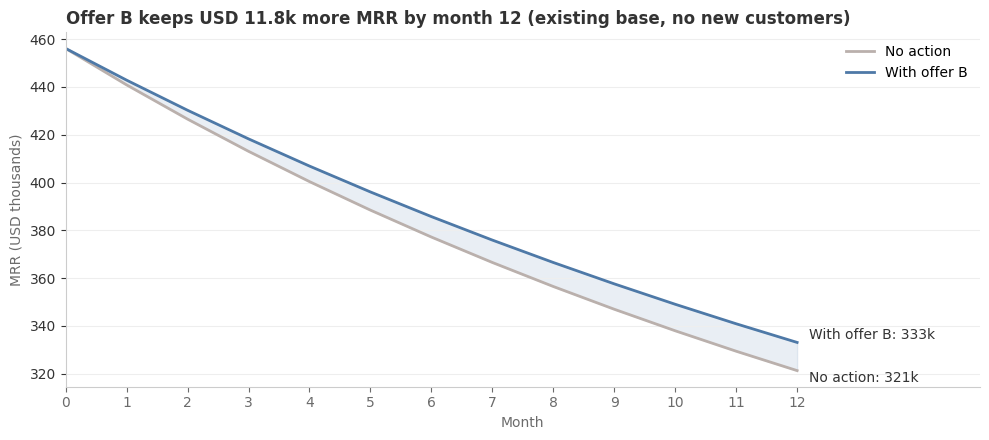

In [184]:
# Step 8c: chart - 12-month MRR forecast of the existing base, with and without offer B
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(forecast.index, forecast["mrr_sin_plan"] / 1000, color=GRAY, linewidth=2, label="No action")
ax.plot(forecast.index, forecast["mrr_con_plan"] / 1000, color=BLUE, linewidth=2, label="With offer B")
ax.fill_between(forecast.index, forecast["mrr_sin_plan"] / 1000, forecast["mrr_con_plan"] / 1000, color=BLUE, alpha=0.12)

# Direct labels at the end of each line (the reader does not need to look up the legend)
fin = forecast.iloc[-1]
ax.text(12.2, fin["mrr_con_plan"] / 1000 + 3, f"With offer B: {fin['mrr_con_plan'] / 1000:.0f}k", va="center", color=INK)
ax.text(12.2, fin["mrr_sin_plan"] / 1000 - 3, f"No action: {fin['mrr_sin_plan'] / 1000:.0f}k", va="center", color=INK)

ax.set_xlim(0, 15)
ax.set_xticks(range(0, 13))
ax.set_xlabel("Month")
ax.set_ylabel("MRR (USD thousands)")
ax.grid(axis="y", color="#EEEEEE")
ax.legend(loc="upper right", frameon=False)
ax.set_title(f"Offer B keeps USD {fin['diferencia'] / 1000:.1f}k more MRR by month 12 (existing base, no new customers)", loc="left", color=INK, fontweight="bold")
fig.tight_layout()
fig.savefig("charts/mrr_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

### KPI scorecard and 12-month forecast
- **Today:** 7,043 customers, MRR USD 456k, ARPU USD 64.8, annual churn 26.5%, **GRR 69.5%** (the base loses about 30% of its recurring revenue per year to churn), weighted LTV USD 1,066, LTV/CAC 3.6. NRR cannot be computed: the data has no upgrades or downgrades.
- **Forecast (existing base only, no new customers):** without action, MRR falls from USD 456k to **USD 321k** in 12 months. With offer B in segments 1-4, it ends at **USD 333k** (+USD 11.8k per month by month 12, **+USD 98k cumulative revenue** in the year).
- **Caveat:** the cumulative gain is gross revenue. The free month of offer B costs USD 64k, so the first-year net is about +USD 34k; the rest of the value comes after month 12 (captured in the lifetime EV).

In [185]:
# Step 9a: export the data for the Tableau dashboard
# 1) One row per customer, with its segment
cols = ["customerID", "segmento", "Contract", "PaymentMethod", "InternetService", "tenure", "tenure_grupo", "MonthlyCharges", "Churn", "ingreso_perdido"]
df[cols].to_csv("tableau_clientes.csv", index=False)

# 2) One row per segment: size, churn, value, LTV, decision and break-even of offer B
seg = resumen.drop(columns="mes_a_mes").join(ltv[["churn_mensual", "ltv", "payback_meses", "ltv_cac"]]).reset_index()
seg["churn_pct"] = 100 * seg["churn"]
seg = seg.merge(mejor[["segmento", "decision", "ve_segmento"]], on="segmento")
eq_b = tabla.loc[tabla["id"] == "B", ["segmento", "reduccion_minima_pct"]].rename(columns={"reduccion_minima_pct": "equilibrio_B_pct"})
seg = seg.merge(eq_b, on="segmento", how="left")
seg.round(3).to_csv("tableau_segmentos.csv", index=False)

# 3) Monthly forecast
forecast.reset_index().round(1).to_csv("tableau_forecast.csv", index=False)

print(len(df), "customers |", len(seg), "segments |", len(forecast), "months")
seg.round(1)

7043 customers | 6 segments | 13 months


,segmento,clientes,churn,arpu,ingreso_mensual,ingreso_perdido,pct_clientes,pct_ingresos,pct_ingreso_perdido,churn_mensual,ltv,payback_meses,ltv_cac,churn_pct,decision,ve_segmento,equilibrio_B_pct
0,"1 No contract, new, high bill",812,0.7,83.8,68032.2,47981.8,11.5,14.9,34.5,0.1,489.7,6.0,1.6,70.0,B Annual contract + 1 free month,10807.9,24.5
1,"2 No contract, new, low bill",1182,0.4,40.7,48054.2,20319.6,16.8,10.5,14.6,0.0,486.7,12.3,1.6,38.6,B Annual contract + 1 free month,10179.4,21.7
2,"3 No contract, tenured, high bill",1231,0.4,90.7,111701.9,46770.0,17.5,24.5,33.6,0.0,1016.7,5.5,3.4,41.5,B Annual contract + 1 free month,24026.6,21.5
3,"4 No contract, tenured, low bill",650,0.2,45.4,29505.8,5775.6,9.2,6.5,4.2,0.0,857.9,11.0,2.9,18.5,B Annual contract + 1 free month,2918.7,28.7
4,"5 Contract, high bill",1472,0.1,94.3,138794.6,15633.6,20.9,30.4,11.2,0.0,2124.9,5.3,7.1,10.7,No offer,0.0,NaN
5,"6 Contract, low bill",1696,0.0,35.4,60027.8,2650.2,24.1,13.2,1.9,0.0,944.3,14.1,3.1,3.3,No offer,0.0,NaN


## Limitations
- **Snapshot data:** one point in time with no dates. Tenure groups are not real signup cohorts, and the timing of churn is not observed.
- **Churn period:** the churn flag is treated as annual (see LTV assumptions). If it were truly monthly, every LTV would be much lower and the model would need to be re-run.
- **Assumed, not measured:** offer take-up and effectiveness, margin, discount rate and CAC are assumptions. The logit shows associations, not the causal effect of an offer (customers self-select into contracts).
- **Simplifications:** a saved customer is valued at the segment-average LTV, churn rates are constant over time, and offers are not combined (no interaction effects).
- **Sample company:** IBM sample data. Results illustrate the method, not a real business.

## Conclusion
- Revenue loss is concentrated: **2 of 6 segments (29% of customers) explain 68% of lost monthly revenue**.
- A blanket 15% discount would **destroy about USD 239k** of lifetime value, because most recipients would have stayed anyway.
- The best eligible offer is an **annual contract + 1 free month for month-to-month customers (+USD 48k lifetime EV)**, with **no offer for contract customers**.
- The plan pays off only if churn falls by **about 23% among customers who accept** (22-29% by segment), so it should start as a **12-month pilot with a randomized control group**.
- With 25% take-up, the eligible base (3,875 customers) can confirm the assumed effect (about 40%) but not the break-even, which would need 12,722 customers. **Higher take-up** would make the test conclusive (Step 7c).